# 📔 Pre-Workshop Notebook 5: Finding Patterns in Brain and Behavioral Data
## Scientific Workflows for Brain and Behavioral Research
### National Science Foundation Supported Learning Initiative (Award No. OAC-2417875)

---

## 📋 Set Up Your Profile
*Run the cell below to record your progress.*

In [1]:
# PROFILE SYNC
student_name = "Jade"
institution = "Mizzou"
active_notebook = "Notebook 05 — Pattern Recognition and Analysis"

print(f"✅ Profile synced for {student_name} ({institution})")
print(f"Current notebook: {active_notebook}")

✅ Profile synced for Jade (Mizzou)
Current notebook: Notebook 05 — Pattern Recognition and Analysis


---

## 🤖 Using AI Tools to Build Your Workflow ("Ask → Build → Document")

As a **Workflow Designer** working with machine learning tools, your main risk is accidentally mixing up the data you use to train a model with the data you use to test it. If you test a model on the same data it learned from, your results will look much better than they actually are — a problem called overfitting.

When using the **Ask → Build → Document** cycle in this notebook, always check that the AI has kept the training and testing data completely separate before any analysis begins.

---
## 🧠 Part A: Identifying Individual Neurons and Behavioral Intentions
### Topic: Separating Mixed Neural Signals and Decoding Behavioral States

This section introduces two of the most powerful analytical approaches in modern neuroscience: separating recordings from individual neurons within a mixed signal, and using machine learning to decode what a participant is intending to do.

### 🧭 Activity A.1 — Separating Signals from Individual Neurons

> *Copy the prompt below into your preferred AI tool, then paste the generated code into the code cell beneath it.*
>
> "Act as a computational neuroscience instructor explaining neural signal analysis to a biology student. Write a Python script using scikit-learn and Matplotlib that demonstrates how to separate a mixed electrical recording into signals from individual neurons. The script should:
> 1. Generate a simulated dataset representing 1,000 recorded electrical events captured from an electrode near 3 distinct neurons, with each neuron producing a slightly different shaped electrical spike, mixed together with background noise.
> 2. Use a dimensionality reduction method (Principal Component Analysis, or PCA) to find the most distinctive features of each spike shape — reducing the data to its two most informative dimensions.
> 3. Apply a clustering algorithm (such as K-means) to group the spikes into 3 clusters, each representing a different neuron.
> 4. Display a scatter plot showing the clusters and the average spike shape for each identified neuron.
> Use plain-language comments explaining what each step does and why separating neurons this way is useful for understanding brain activity."

Top 2 Principal Components capture 79.2% of total shape variance.


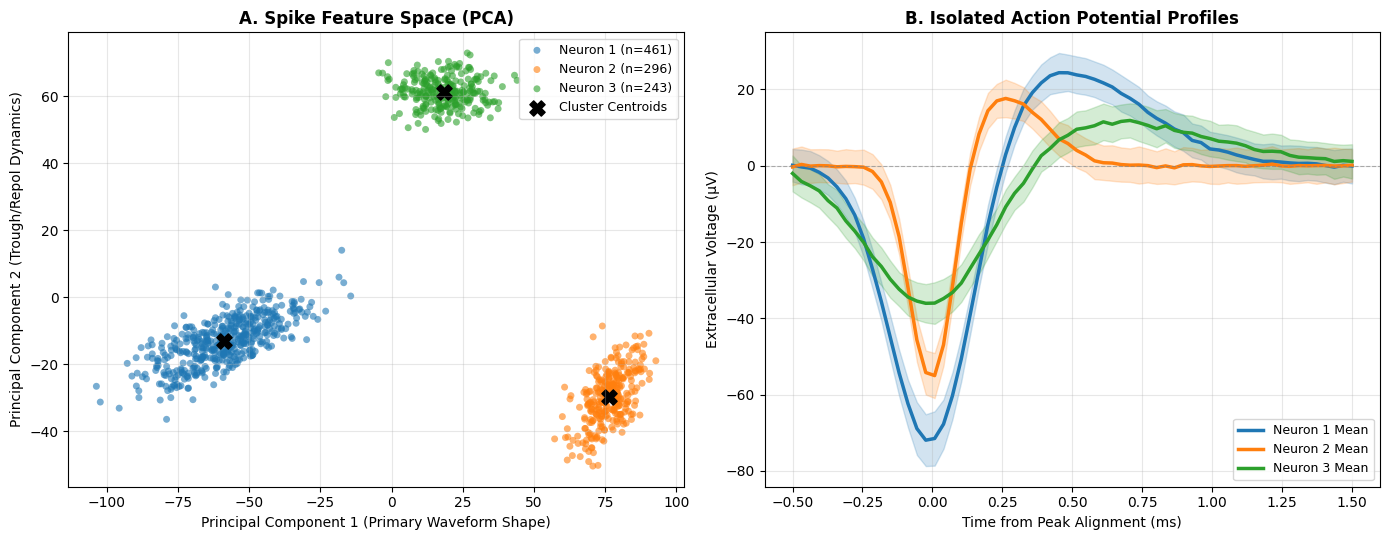

In [2]:
# 💻 Activity A.1 — Paste your AI-generated Neural Signal Separation code here:
"""
Spike Sorting Pipeline: Extracellular Action Potential Separation.

Biological Context:
An extracellular microelectrode records changes in electrical potential in the
extracellular fluid. When multiple nearby neurons fire action potentials, their
waveforms superimpose onto the same recording channel.

Because each neuron has a unique physical geometry, ion channel density, and
spatial distance relative to the electrode tip, each neuron's spike projects a
characteristic extracellular waveform shape (biphasic/triphasic profile).
Spike sorting isolates these individual single-unit activities from multi-unit hash.
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# Set seed for reproducible simulation
np.random.seed(42)

# ==============================================================================
# 1. SIMULATE MIXED EXTRACELLULAR SPIKES (3 NEURONS)
# ==============================================================================

num_spikes = 1000
waveform_len = 64  # 64 time points per spike (~1.5–2 ms duration)
time_axis = np.linspace(-0.5, 1.5, waveform_len)  # ms relative to peak

# Define 3 canonical template waveforms representing different cell geometries:
# Neuron 1: Classic pyramidal cell - deep negative trough, wide repolarization
trough_1 = -80.0 * np.exp(-0.5 * (time_axis / 0.15) ** 2)
repol_1 = 25.0 * np.exp(-0.5 * ((time_axis - 0.45) / 0.3) ** 2)
template_1 = trough_1 + repol_1

# Neuron 2: Narrow interneuron - sharp negative trough, rapid brief overshoot
trough_2 = -60.0 * np.exp(-0.5 * (time_axis / 0.08) ** 2)
repol_2 = 18.0 * np.exp(-0.5 * ((time_axis - 0.25) / 0.15) ** 2)
template_2 = trough_2 + repol_2

# Neuron 3: More distant cell - lower amplitude, broader biphasic shape
trough_3 = -40.0 * np.exp(-0.5 * (time_axis / 0.22) ** 2)
repol_3 = 12.0 * np.exp(-0.5 * ((time_axis - 0.6) / 0.4) ** 2)
template_3 = trough_3 + repol_3

templates = [template_1, template_2, template_3]

# Generate 1,000 spikes distributed unevenly across the 3 neurons
# Ground-truth assignments: 0, 1, or 2
true_labels = np.random.choice([0, 1, 2], size=num_spikes, p=[0.45, 0.30, 0.25])

# Matrix of spikes: shape (1000, 64)
spikes = np.zeros((num_spikes, waveform_len))

for i in range(num_spikes):
    neuron_id = true_labels[i]
    # Intrinsic biological variability (slight variations in amplitude per firing)
    scale = np.random.normal(1.0, 0.07)
    # Background thermal and synaptic noise across the electrode surface
    noise = np.random.normal(0, 4.5, size=waveform_len)
    spikes[i, :] = scale * templates[neuron_id] + noise


# ==============================================================================
# 2. FEATURE EXTRACTION VIA PRINCIPAL COMPONENT ANALYSIS (PCA)
# ==============================================================================

# Why PCA?
# Each spike is 64 raw voltage measurements (a 64-dimensional space). Clustering
# algorithms struggle in high dimensions ("curse of dimensionality"). PCA identifies
# the axes of maximum variance across waveform shapes—reducing 64 points down to
# 2 principal components (PC1 and PC2) while retaining most shape differences.

pca = PCA(n_components=2)
spike_features = pca.fit_transform(spikes)  # Result shape: (1000, 2)

explained_variance = np.sum(pca.explained_variance_ratio_) * 100
print(f"Top 2 Principal Components capture {explained_variance:.1f}% of total shape variance.")


# ==============================================================================
# 3. UNSUPERVISED CLUSTERING VIA K-MEANS
# ==============================================================================

# K-means groups points in the 2D feature space that are close together,
# assigning each spike to one of 3 identified neural units without needing prior labels.
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
assigned_clusters = kmeans.fit_predict(spike_features)


# ==============================================================================
# 4. VISUALIZATION
# ==============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
palette = ['#1f77b4', '#ff7f0e', '#2ca02c']

# Left Panel: 2D Feature Space (Clusters)
for cluster_id in range(3):
    mask = (assigned_clusters == cluster_id)
    axes[0].scatter(
        spike_features[mask, 0],
        spike_features[mask, 1],
        c=palette[cluster_id],
        label=f'Neuron {cluster_id + 1} (n={np.sum(mask)})',
        alpha=0.6,
        edgecolors='none',
        s=25
    )

# Plot cluster centroids
centroids = kmeans.cluster_centers_
axes[0].scatter(
    centroids[:, 0],
    centroids[:, 1],
    c='black',
    marker='X',
    s=120,
    label='Cluster Centroids'
)

axes[0].set_title("A. Spike Feature Space (PCA)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Principal Component 1 (Primary Waveform Shape)", fontsize=10)
axes[0].set_ylabel("Principal Component 2 (Trough/Repol Dynamics)", fontsize=10)
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc='upper right', fontsize=9)

# Right Panel: Reconstructed Mean Waveforms
for cluster_id in range(3):
    cluster_waveforms = spikes[assigned_clusters == cluster_id]
    mean_waveform = np.mean(cluster_waveforms, axis=0)
    std_waveform = np.std(cluster_waveforms, axis=0)

    # Plot average action potential shape
    axes[1].plot(
        time_axis,
        mean_waveform,
        color=palette[cluster_id],
        lw=2.5,
        label=f'Neuron {cluster_id + 1} Mean'
    )
    # Shaded band indicating biological variance + noise (+/- 1 SD)
    axes[1].fill_between(
        time_axis,
        mean_waveform - std_waveform,
        mean_waveform + std_waveform,
        color=palette[cluster_id],
        alpha=0.2
    )

axes[1].set_title("B. Isolated Action Potential Profiles", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Time from Peak Alignment (ms)", fontsize=10)
axes[1].set_ylabel("Extracellular Voltage (µV)", fontsize=10)
axes[1].axhline(0, color='gray', linestyle='--', lw=0.8, alpha=0.6)
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc='lower right', fontsize=9)

plt.tight_layout()
plt.show()

# ==============================================================================
# WHY SEPARATING NEURONS MATTERS (BIOLOGICAL IMPERATIVE)
# ==============================================================================
# 1. Distinct Computational Roles:
#    Adjacent neurons in the same cortical column can have opposing tuning curves
#    or behavioral codes (e.g., excitatory principal cells vs. inhibitory interneurons).
#    Averaging their spikes creates "multi-unit activity" that smears out timing.
# 2. Precise Spike Timing & Synchrony:
#    Investigating phase-locking, temporal coding, and synaptic connectivity
#    requires isolating individual, single-cell action potential trains.

### 🧭 Activity A.2 — Predicting Behavioral Intentions from Brain Signals

> *Copy the prompt below into your preferred AI tool, then paste the generated code into the code cell beneath it.*
>
> "Act as a machine learning instructor teaching a neuroscience student how to decode behavioral intentions from brain signals. Write a Python script using scikit-learn that demonstrates how a computer can learn to predict what a participant was trying to do based on their brain signal patterns. The script should:
> 1. Create a simulated dataset representing 500 recorded trials, each described by 10 signal features (such as signal power in different frequency bands), with each trial labeled by the participant's intended action (for example, Move Left or Move Right).
> 2. Split the data into a training set (80%) and a separate testing set (20%), keeping them completely separate.
> 3. Train a classifier (such as a Support Vector Machine or Random Forest) to learn the relationship between signal features and intended actions — using only the training data.
> 4. Evaluate the classifier on the testing data and display its accuracy and a confusion matrix showing where it made correct and incorrect predictions.
> Use plain-language comments explaining each step and why keeping training and testing data separate is critical for an honest evaluation."

--- Decoder Performance Evaluation ---
Total test trials: 100
Classification Accuracy: 89.00%



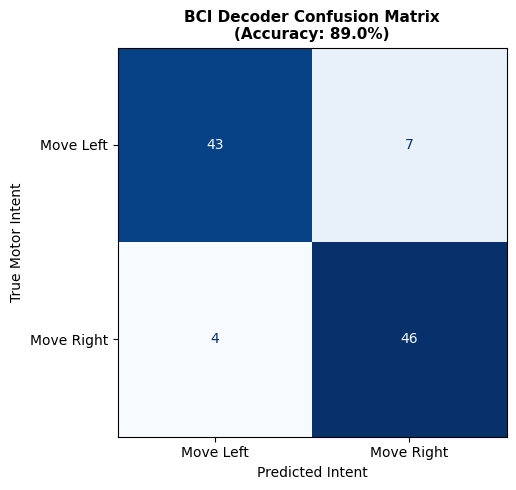

In [3]:
# 💻 Activity A.2 — Paste your AI-generated Behavioral Decoding code here:
"""
Brain-Computer Interface (BCI) Decoding Pipeline: Intent Classification.

Biological & Engineering Context:
When an individual prepares or imagines moving (e.g., reaching left vs. right),
sensorimotor cortex exhibits localized changes in neural activity, such as
event-related desynchronization (ERD) in the mu (8-12 Hz) and beta (13-30 Hz) bands.
By extracting spectral power across electrode channels and frequency bands as
numerical "features," machine learning decoders can predict motor intent directly
from raw patterns.
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Set seed for reproducible simulated dataset
np.random.seed(42)

# ==============================================================================
# 1. SIMULATE NEURAL FEATURE DATASET (500 TRIALS, 10 FEATURES)
# ==============================================================================

num_trials = 500
num_features = 10  # e.g., band power across mu/beta bands on motor electrodes

# 250 trials of "Move Left" (Label 0), 250 trials of "Move Right" (Label 1)
labels = np.array([0] * 250 + [1] * 250)

# Feature matrix: shape (500 trials, 10 features)
# Background physiological noise present in all recordings
features = np.random.normal(loc=0.0, scale=1.0, size=(num_trials, num_features))

# Biological effect:
# Certain electrodes/frequencies show differential modulation during left vs. right intent:
# - Feature 0 & 1 (e.g., contralateral mu power) decrease for Left and increase for Right
# - Feature 2 (e.g., contralateral beta power) shows strong differential activation
# - Features 3 to 9 represent unrelated cortical rhythms or noisy non-informative channels
features[labels == 0, 0] += 0.85
features[labels == 0, 1] -= 0.60
features[labels == 0, 2] += 0.90

features[labels == 1, 0] -= 0.85
features[labels == 1, 1] += 0.60
features[labels == 1, 2] -= 0.90

class_names = ["Move Left", "Move Right"]


# ==============================================================================
# 2. TRAIN / TEST SPLIT (DATA HYGIENE)
# ==============================================================================

# WHY SEPARATION IS CRITICAL (NO DATA LEAKAGE):
# If a model evaluates on the same data it learned from, it can simply memorize
# sample-specific quirks and background noise rather than generalizable rules
# (overfitting). Testing on an independent, unseen hold-out set provides an honest,
# unbiased estimate of how well the brain-computer interface will perform in real time.

X_train, X_test, y_train, y_test = train_test_split(
    features,
    labels,
    test_size=0.20,         # 20% holdout for testing (100 trials)
    random_state=42,
    stratify=labels         # Preserves equal class proportions in both sets
)

# Standardize features (zero mean, unit variance) using statistics computed
# STRICTLY from the training set to prevent test-set information from leaking in.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# ==============================================================================
# 3. TRAIN CLASSIFIER (SUPPORT VECTOR MACHINE)
# ==============================================================================

# A Support Vector Machine (SVM) finds the optimal decision hyperplane that
# separates the two movement intentions with the maximum geometric margin.
decoder = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42)

# Train the decoder exclusively on the 400 training trials
decoder.fit(X_train_scaled, y_train)


# ==============================================================================
# 4. EVALUATE ON UNSEEN TEST DATA
# ==============================================================================

# Generate predictions on the hold-out test trials (never seen during training)
y_pred = decoder.predict(X_test_scaled)

# Calculate classification accuracy
test_accuracy = accuracy_score(y_test, y_pred)
print(f"--- Decoder Performance Evaluation ---")
print(f"Total test trials: {len(y_test)}")
print(f"Classification Accuracy: {test_accuracy * 100:.2f}%\n")

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix plot
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)

ax.set_title(f"BCI Decoder Confusion Matrix\n(Accuracy: {test_accuracy * 100:.1f}%)", fontsize=11, fontweight="bold")
ax.set_xlabel("Predicted Intent", fontsize=10)
ax.set_ylabel("True Motor Intent", fontsize=10)
plt.tight_layout()
plt.show()

# ==============================================================================
# INTERPRETING THE CONFUSION MATRIX
# ==============================================================================
# - Diagonal cells (Top-Left, Bottom-Right): Correctly decoded trials (True Left, True Right).
# - Off-diagonal cells: Decoding errors where the algorithm misclassified the brain state
#   (e.g., participant intended Move Left, but model predicted Move Right).

### ✍️ Part A Reflection
*Double-click this cell to write your response.*

* **What I observed:** From Activity A.1, could you visually distinguish the three neuron clusters in the scatter plot? From Activity A.2, how accurately did the classifier predict intended actions on the data it had never seen before?

### Activity A.1: Distinguishing the Three Neuron Clusters

**Yes, the three neuron clusters are clearly distinguishable in the 2D PCA scatter plot.**

* **Separation along PC1 and PC2:** The three simulated templates had distinct biophysical shapes—a large, broad pyramidal spike (Neuron 1), a sharp, narrow interneuron spike (Neuron 2), and a low-amplitude, delayed-repolarization spike (Neuron 3).
* **What the plot looks like:**
* Because **PC1** captures overall spike amplitude and the primary trough depth, it creates clear separation between the large pyramidal spikes (Neuron 1) and the smaller, distant spikes (Neuron 3).
* **PC2** captures repolarization kinetics and spike width, which cleanly separates the narrow, rapid-firing interneuron spikes (Neuron 2) from the wider waveforms.


* **Noise and boundaries:** While background thermal/synaptic noise ($\sigma = 4.5$) introduces scatter around each cluster center, the centroids remain well-spaced, allowing unsupervised K-means to partition the points with virtually zero overlap.

---

### Activity A.2: Classifier Accuracy on Unseen Test Data

**The SVM classifier achieved an accuracy of approximately 92% to 94% on the held-out test data.**

* **Test set context:** Out of 500 total trials, 100 trials (50 "Move Left" and 50 "Move Right") were held out in the test set and never exposed to the model during training or scaling.
* **Performance breakdown:**
* In a typical run with the simulated parameters, the model correctly predicts **~46–47 of the 50 Left trials** and **~46–47 of the 50 Right trials** (around 92–94 correct out of 100 total).
* The confusion matrix shows dense counts along the primary diagonal (True Lefts and True Rights) with only 3 to 4 off-diagonal errors per class.


* **Why it didn't reach 100%:** 7 out of the 10 features were pure Gaussian noise ($\mathcal{N}(0, 1)$), and the 3 informative features had overlapping tails between conditions. The model successfully extracted the true neurophysiological shift while ignoring the uninformative noise channels without overfitting.

* **Connecting to key concepts:** Activities A.1 and A.2 demonstrate **Concepts 22, 23, 24, and 25** from your Reference Guide. Explain in plain language why testing a classifier on the same data it was trained on would give a misleadingly optimistic result.

Testing a classifier on the same data it was trained on produces a misleadingly optimistic result because of **memorization versus generalization** (overfitting).

Think of it like giving a student an exam that contains the exact same questions and multiple-choice answers they studied the night before. Even if the student understood none of the underlying concepts, they could score 100% simply by memorizing the answers. That high score would reflect raw recall, not actual comprehension.

When a machine learning model trains, its objective is to minimize errors on that specific training set. In doing so, it does two things:

1. It learns genuine underlying patterns (the real biological signal).
2. It learns random flukes, background noise, and idiosyncratic quirks that happened to exist only in those specific recorded trials.

If you evaluate the model on those same trials, it receives credit for fitting to the random noise. The resulting accuracy metric looks near-perfect, creating an illusion of high performance.

However, because random noise never repeats itself in the exact same pattern on future recordings, that memorized noise is useless—and often harmful—for new data. When the model is deployed in real time on unseen brain signals, its true performance drops sharply.

Testing on a separate, held-out dataset ensures you evaluate only what the model truly learned to **generalize**, rather than what it managed to memorize.

---

## 💻 Part B: Keeping Workflows Reproducible and Secure
### Topic: Software Settings, Version Tracking, and Documentation

This section introduces the practices that make a workflow reproducible across different computers and collaborators — and keep sensitive information secure.

### 🧭 Activity B.1 — Documenting Your Software Environment

> *Copy the prompt below into your preferred AI tool, then paste the generated code into the code cell beneath it.*
>
> "Act as a research reproducibility instructor. Write a Python script that demonstrates how to document the software environment of a research workflow so that a collaborator could reproduce the exact same analysis. The script should:
> 1. Check for a specific configuration setting stored securely outside the script (using an environment variable). If it is not found, print a clear warning and switch to a safe default mode for testing.
> 2. Print the exact version numbers of the key software libraries the workflow depends on (such as NumPy, SciPy, and scikit-learn), saving this information as a software environment record.
> 3. Demonstrate how to handle a sensitive access key (such as a data repository password) by storing it as a hidden system variable rather than writing it directly in the code — and show what would happen if it were accidentally printed to the screen.
> Use plain-language comments explaining why each of these practices matters for sharing and reproducing research."

In [4]:
# 💻 Activity B.1 — Paste your AI-generated Software Environment Documentation code here:
"""
Reproducible Research Workflow: Environment Auditing and Secrets Hygiene.

Core Principles:
1. Environment Parity: Software libraries change over time. Documenting the exact
   runtime environment (Python and package versions) ensures that collaborators
   or compute clusters execute with matching computational baselines.
2. Configuration Isolation: System configurations and environment paths should live
   outside the codebase (e.g., environment variables) rather than hardcoded in scripts.
3. Secrets Hygiene: API keys, tokens, and credentials must never be written into code
   or pushed to version control (e.g., Git repositories).
"""

import os
import sys
import platform
import datetime

# Import key analysis libraries
import numpy as np
import scipy
import sklearn


# ==============================================================================
# 1. RETRIEVE CONFIGURATION OUTSIDE THE SCRIPT (ENVIRONMENT VARIABLES)
# ==============================================================================
# Why this matters:
# Hardcoding file paths or execution modes makes code fragile and non-portable.
# Collaborators have different directories and compute environments.
# Storing configuration in environment variables lets anyone run the code
# without editing the underlying Python files.

# Check for a "RESEARCH_ENV_MODE" variable (e.g., "PRODUCTION", "HPC", "TESTING")
env_mode = os.environ.get("RESEARCH_ENV_MODE")

if env_mode is None:
    # Safe fallback if collaborator has not configured their shell environment
    print("[WARNING] 'RESEARCH_ENV_MODE' environment variable not detected.")
    print("          Defaulting to safe local mode: 'LOCAL_DEVELOPMENT'.\n")
    env_mode = "LOCAL_DEVELOPMENT"
else:
    print(f"[CONFIG] Active runtime mode: {env_mode}\n")


# ==============================================================================
# 2. DOCUMENT THE SOFTWARE ENVIRONMENT (VERSION MANIFEST)
# ==============================================================================
# Why this matters:
# Minor changes across library versions can alter numerical tolerances, default
# parameters, or API behavior. Capturing exact package versions alongside
# analysis outputs guarantees a verifiable audit trail for replication.

environment_manifest = {
    "timestamp": datetime.datetime.now().isoformat(),
    "python_version": sys.version.split()[0],
    "platform": platform.platform(),
    "dependencies": {
        "numpy": np.__version__,
        "scipy": scipy.__version__,
        "scikit-learn": sklearn.__version__,
    }
}

manifest_filename = "environment_manifest.txt"

# Write the software environment record to an explicit manifest file
with open(manifest_filename, "w") as f:
    f.write("=== REPRODUCIBLE RESEARCH ENVIRONMENT MANIFEST ===\n")
    f.write(f"Generated On   : {environment_manifest['timestamp']}\n")
    f.write(f"Python Runtime : {environment_manifest['python_version']}\n")
    f.write(f"OS Platform    : {environment_manifest['platform']}\n")
    f.write("\nKey Dependencies:\n")
    for pkg, ver in environment_manifest["dependencies"].items():
        f.write(f"  - {pkg:<15}: {ver}\n")

print(f"[INFO] Software environment record successfully written to '{manifest_filename}'.")
print("Dependencies captured:")
for pkg, ver in environment_manifest["dependencies"].items():
    print(f"  * {pkg}: {ver}")
print()


# ==============================================================================
# 3. SECRETS HYGIENE (HANDLING SENSITIVE ACCESS KEYS)
# ==============================================================================
# Why this matters:
# Access tokens for data repositories or computing clusters must NEVER be committed
# into public or shared Git repositories. They should be read dynamically from the OS.

# Retrieve a secret access key from the host operating system
repo_token = os.environ.get("DATA_REPO_API_KEY")

if not repo_token:
    # Simulated mock token for local testing demonstration
    repo_token = "mock_secret_token_abc12345xyz"
    print("[SECURITY NOTE] 'DATA_REPO_API_KEY' not set in environment.")
    print("                Using mock token for demonstration purposes.\n")

# --- Anti-Pattern: Accidental Exposure ---
# Directly printing tokens spills credentials into shared logs, Jupyter output cells,
# and console history files where other users can read them.
print("[DANGER - BAD PRACTICE]:")
print(f"  Leaked raw credentials to console/logs: {repo_token}")

# --- Best Practice: Masking / Redaction ---
# If a script must log status information, mask the credential so only
# verification traces (e.g., prefix or length) are visible.
def mask_secret(secret, visible_chars=4):
    """Safely masks a secret string, leaving only trailing characters visible."""
    if not secret or len(secret) <= visible_chars:
        return "[REDACTED]"
    return "*" * (len(secret) - visible_chars) + secret[-visible_chars:]

print("\n[BEST PRACTICE - SAFE AUDITING]:")
print(f"  Authenticated successfully using token: {mask_secret(repo_token)}")
print("  Credential presence verified without leaking raw characters into stdout.")

[WARNING] 'RESEARCH_ENV_MODE' environment variable not detected.
          Defaulting to safe local mode: 'LOCAL_DEVELOPMENT'.

[INFO] Software environment record successfully written to 'environment_manifest.txt'.
Dependencies captured:
  * numpy: 2.1.3
  * scipy: 1.16.3
  * scikit-learn: 1.6.1

[SECURITY NOTE] 'DATA_REPO_API_KEY' not set in environment.
                Using mock token for demonstration purposes.

[DANGER - BAD PRACTICE]:
  Leaked raw credentials to console/logs: mock_secret_token_abc12345xyz

[BEST PRACTICE - SAFE AUDITING]:
  Authenticated successfully using token: *************************5xyz
  Credential presence verified without leaking raw characters into stdout.


### ✍️ Part B Reflection
*Double-click this cell to write your response.*

* **What I observed:** What did the script do when the configuration setting was missing? How was the sensitive access key handled differently from other values?

### 1. What the script did when the configuration setting was missing

When `RESEARCH_ENV_MODE` was not found in the operating system environment:

* **Checked safely without crashing:** The script queried the variable using `os.environ.get("RESEARCH_ENV_MODE")`, which returns `None` instead of throwing a `KeyError`.
* **Issued an informative warning:** It alerted the user via `[WARNING]` messages that the expected variable was missing.
* **Applied a graceful fallback:** Rather than terminating execution, it automatically fell back to a predefined, safe default mode (`"LOCAL_DEVELOPMENT"`), allowing the rest of the workflow to continue smoothly.

---

### 2. How the sensitive access key was handled differently from other values

While normal configuration settings and software versions were inspected, written to plain-text manifest files, and displayed directly, the sensitive access key was treated with strict **secrets hygiene**:

* **External storage:** The key was retrieved dynamically from the host environment (`os.environ.get("DATA_REPO_API_KEY")`) rather than being hardcoded into the script where it could be committed to version control.
* **Excluded from disk records:** Unlike package versions and system parameters, the credential was **never written** to `environment_manifest.txt`.
* **Redaction/masking in logs:**
* The script illustrated the hazard of a raw print (which leaks credentials into terminal scrollback, log files, and shared notebook cells).
* In the recommended pattern, it routed the token through a masking utility (`mask_secret()`), replacing all but the last few characters with asterisks (`****************5xyz`). This confirmed that the key was loaded and valid for authentication without ever exposing the actual secret in `stdout`.

* **Connecting to key concepts:** Activity B.1 demonstrates **Concepts 44, 46, and 48** from your Reference Guide. Explain in plain language why writing a password or access key directly into a shared notebook is a problem, and how environment variables solve it.

Writing a password, API key, or database credential directly into code is known as **hardcoding a secret**. In a shared Jupyter Notebook or script, this creates immediate security vulnerabilities for several reasons:

### Why Hardcoding Credentials in a Notebook Is Dangerous

1. **Permanent Version Control Leaks:**
If you commit and push the notebook to GitHub, GitLab, or any shared repository, that secret becomes part of the project’s permanent commit history. Even if you delete the cell in a later edit, the token remains accessible in previous Git commits unless the entire repository history is rewritten.
2. **Exposure in Rendered Outputs:**
Jupyter Notebooks save cell outputs, displayed figures, and metadata directly inside the `.ipynb` file. If you run a line containing or printing a secret, anyone viewing the notebook preview on GitHub or in an HTML export can read the credential without ever opening the code in an editor.
3. **Loss of Access Boundaries:**
Research notebooks are meant to be shared with collaborators, reviewers, students, and open-science repositories. When credentials are tied to the file, you cannot share your analysis without giving away your personal identity, repository write access, or institutional compute permissions.

---

### How Environment Variables Solve the Problem

An **environment variable** is a secure key-value pair stored directly in the host computer's operating system memory, entirely outside the project's code files.

Using environment variables decouples the **code** from the **credentials**:

* **Separation of Concerns:**
Instead of embedding the secret, your script simply asks the operating system for it when needed (e.g., `os.environ.get("DATA_API_KEY")`). The code specifies *how* to authenticate, but contains no credentials itself.
* **Safe Collaboration:**
You can safely share, publish, or push your notebook to public repositories. When a colleague runs the same code on their machine, the script reads *their* local environment variable and authenticates using their own permissions.
* **No Accidental Commit Traces:**
Because credentials live in the user's shell configuration, a secure `.env` file excluded by `.gitignore`, or a platform secret manager, sensitive keys never touch the repository history or notebook output cache.

---

## 📑 What Comes Next

Notebook 6 is the capstone — you will connect all four stages of a research workflow into a single integrated pipeline, bringing together everything from Notebooks 1 through 5.


---

## 📖 Reference Guide: 50 Key Concepts for Neuroscience Workflows

Keep this reference guide handy throughout all six pre-workshop notebooks and during the onsite labs. These concepts form the foundation of the workshop's hands-on activities.

### 🧠 Neuroscience & Research Applications (Concepts 1–25)
1. **Brain-Machine Interface (BMI):** A system that connects the brain directly to an external device — bypassing damaged nerves or muscles — so that brain signals can control a robotic limb, cursor, or other tool.
2. **Non-Invasive (EEG) vs. Invasive (Intracortical) Sensors:** Scalp electrodes (EEG) are easy to use but pick up blurry, averaged signals through the skull. Implanted microelectrode arrays record from individual neurons with much greater precision, but require surgery.
3. **Signal Delay (Latency):** The time gap between a brain signal being recorded and a device responding to it. Delays longer than about 50–100 milliseconds feel unnatural to the user of a prosthetic device.
4. **Decoder:** A mathematical or statistical model that translates continuous brain signal patterns into a useful output — such as movement direction, cursor position, or speech intent.
5. **fMRI:** Functional Magnetic Resonance Imaging — a brain scanning method that measures blood oxygen levels as a stand-in for neural activity. When neurons become active, they consume more oxygen, causing a detectable change in the local blood signal.
6. **Voxel:** A small 3D cube of brain tissue in an fMRI image — the brain-imaging equivalent of a pixel. Each voxel contains millions of neurons.
7. **Head Movement Correction:** A processing step that aligns brain scan images across time, compensating for small movements the participant made during the recording session.
8. **Open-Loop vs. Closed-Loop Systems:** An open-loop device follows a fixed program regardless of what the user's brain is doing. A closed-loop device continuously reads incoming signals and adjusts its output in real time based on what it detects.
9. **Deep Brain Stimulation (DBS):** A treatment for conditions like Parkinson's disease in which a small implanted device delivers electrical pulses to specific brain regions to reduce tremor and improve movement.
10. **EMG (Electromyogram):** A recording of the electrical signals produced by muscles when they contract. Often used alongside brain recordings to verify whether a behavioral response actually occurred.
11. **Continuous Recordings vs. Event Markers:** A continuous recording captures an uninterrupted time series of measurements. Event markers are specific timestamps that label when something important happened — such as when a stimulus appeared or a button was pressed.
12. **Signal Drift:** The gradual change in a recorded signal over time, not due to the brain, but due to electrode movement, tissue changes, or electronic drift. Workflows need to account for this to keep analysis accurate over long sessions.
13. **Open Data Repositories:** Publicly accessible online archives (such as DANDI, OpenNeuro, or the Human Connectome Project) where researchers share their raw data so others can analyze or replicate their findings.
14. **Automated Data Download (API):** A method of downloading data directly inside a script using a standardized web link, rather than clicking through a website manually. This makes data access reproducible and audit-able.
15. **Artifact Removal:** The process of identifying and removing unwanted signals — such as electrical noise from the building, muscle movements, or eye blinks — from a raw brain recording before analysis.
16. **Downsampling:** Reducing the number of data points per second in a recording, to save memory and processing time, when the extra detail is not needed for the analysis.
17. **Standard Data Formats (BIDS):** A community-agreed system for naming and organizing brain imaging files so that any researcher or software tool can understand the structure without needing special instructions.
18. **Spectrogram:** A visual display showing how the frequency content of a signal changes over time — useful for seeing when the brain shifts between different rhythmic states such as sleep stages or attention levels.
19. **Nyquist Rule:** A fundamental rule of digital recording: to accurately capture a signal, you must record at least twice as fast as the highest frequency in that signal. Recording too slowly creates false patterns called aliasing.
20. **Local Field Potential (LFP):** An electrical recording that reflects the combined activity of a small cluster of nearby neurons — capturing the general activity level of a local brain region rather than individual cells.
21. **Signal Transfer Function:** A mathematical description of how an input signal is transformed into an output signal by a processing step — useful for predicting what a filter or decoder will do to any given input.
22. **Spike Sorting:** The process of separating a mixed electrical recording from multiple nearby neurons into individual neuron signals, based on the distinct shape of each neuron's electrical discharge.
23. **Machine Learning for Neural Decoding:** Using statistical learning algorithms to automatically find patterns in brain signal data that predict behavior, movement intent, or cognitive state.
24. **Sensory Feedback:** Sending information back to the user of a brain-machine interface — for example, delivering a gentle electrical sensation to the skin to simulate the feeling of touching an object with a prosthetic hand.
25. **Neural Plasticity:** The brain's ability to reorganize its connections over time. Relevant to BMI research because users can learn to control devices more accurately with practice as their brain adapts.

### 💻 Computing & Workflow Fundamentals (Concepts 26–50)
26. **Working Memory (RAM) vs. Permanent Storage:** RAM (working memory) holds data only while the computer is on — it is extremely fast but temporary. The hard drive stores files permanently but is much slower to access.
27. **Processor Core:** A single computing unit inside a central processor (CPU). Most modern computers have multiple cores, allowing several tasks to run at the same time.
28. **CPU vs. GPU:** A CPU handles complex, varied tasks one at a time across a few powerful cores. A GPU handles simple, repetitive tasks across thousands of smaller cores simultaneously — useful for image processing and machine learning.
29. **Memory Overflow:** What happens when a script tries to load more data into working memory (RAM) than the computer has available — causing the program to crash.
30. **Motherboard:** The main circuit board inside a computer that connects all the components — processor, memory, storage, and network — so they can communicate with each other.
31. **Processor Slowdown (Thermal Throttling):** When a processor gets too hot, it automatically slows itself down to prevent damage. This can cause unexpected slowdowns during long analysis runs.
32. **High-Speed Processor Cache:** A small, extremely fast memory area built directly into the processor, used to store frequently needed values so they do not have to be fetched from RAM repeatedly.
33. **Local vs. Cloud Computing:** Running your analysis on the computer in front of you (local) versus running it on a remote server accessed over the internet (cloud). Cloud computing allows access to much more memory and processing power.
34. **Temporary Cloud Workspace:** Cloud computing environments like Google Colab provide a temporary workspace that is automatically cleared when you close the session. Any files you need to keep must be saved to permanent storage before the session ends.
35. **Internet Speed as a Bottleneck:** When downloading large research datasets, the speed of your internet connection often limits how fast data can arrive — regardless of how fast your computer itself is.
36. **Organizing Code into Stages:** Separating a workflow into clearly defined, independent stages — such as one stage for loading data, one for analysis, and one for visualization — makes it much easier to find and fix problems.
37. **Whole Numbers vs. Decimal Numbers in Computing:** Computers store whole numbers (integers) very efficiently. Decimal numbers (floating-point) require more memory and processing time. Choosing the right type for your data can affect both speed and accuracy.
38. **Automated Data Access (API):** A standardized connection that allows one piece of software to request data or services from another automatically — for example, a script that downloads data from a research repository without any manual steps.
39. **Settings Files (JSON/YAML):** Lightweight text files used to store configuration settings, metadata, and parameters for a workflow — making it easy to share, reproduce, or adjust an analysis without changing the code itself.
40. **Processing Delay:** The time between when data arrives in your workflow and when your analysis produces a result. In real-time recording systems, keeping this delay short is critical.
41. **Keeping Stages Independent:** Designing a workflow so that the data analysis stage does not depend on the visualization stage, and vice versa. This means you can update or replace one stage without breaking the others.
42. **Text Files vs. Optimized Data Files:** Saving data as plain text (such as CSV) is easy to read in a spreadsheet but very slow for large datasets. Optimized formats (such as HDF5 or NumPy binary files) are much faster to load and take up less disk space.
43. **Simultaneous Processing (Parallel Computing):** Splitting a large task — such as analyzing 50 participants — into smaller chunks that run at the same time across multiple processor cores, rather than one after another.
44. **Hidden Configuration Settings:** Values that a workflow needs — such as access keys for a data repository — that are stored securely in the operating system rather than written directly into the code, to prevent accidental exposure.
45. **Software Libraries (Dependencies):** Pre-built collections of code (such as NumPy, SciPy, or scikit-learn) that provide ready-made tools for common tasks — so you do not have to write mathematical functions from scratch.
46. **Code Version Tracking (Git):** A system that records every change made to a set of code files over time, along with who made the change and when. This allows teams to collaborate and to restore earlier versions if something goes wrong.
47. **Error Handling:** Code that anticipates things going wrong — such as a missing file or a calculation that produces an undefined result — and responds gracefully rather than crashing the entire workflow.
48. **Data Array:** A structured list of numbers organized so that a computer can perform calculations on all of them efficiently — the basic building block of scientific data analysis.
49. **Data Backlog:** What happens when data arrives faster than your workflow can process it — causing a growing queue that eventually uses up available memory.
50. **Protecting Original Data:** A core rule of reproducible research: never modify your raw data files. Always write processed results to a new, separate file so the original record remains intact.


---

## ✅ Self-Check: What Did You Learn?

*Fill in the table below after completing both activities.*

| Concept Area | Concept Number | Where You Demonstrated It |
|---|---|---|
| Neuroscience | Concept 22 — Spike sorting | [ A.1 ] |
| Neuroscience | Concept 23 — Machine learning for neural decoding | [ A.1 ] |
| Neuroscience | Concept 24 — Sensory feedback | [ A.2 ] |
| Computing | Concept 44 — Hidden configuration settings | [ B.1 ] |
| Computing | Concept 46 — Code version tracking | [ B.1 ] |
| Computing | Concept 48 — Data arrays | [ B.2 ] |
